# 360. Do changed k-mers, landed on Pfam domains by kmerseek, find the changed domains as well as Trinity + DIAMOND?

**Claim tested.** Landing differentially expressed k-mers on protein regions with kmerseek, in a
reduced alphabet and with the region score kept, recovers the domains that actually changed at
least as well as assembly, then DIAMOND, then the best hit's Pfam domains, and does so without
assembling the transcriptome.

**What this decides.** Whether the paper can offer kmerseek as a way to read a differential
expression experiment in an organism with no genome or annotation: count k-mers, test them, and
read off which protein domains changed. If the rule below fails, the paper does not make that
offer, and the comparison says by how much the assembly route is ahead.

**Pass/fail rule, frozen before anything ran**
([`360_data/preregistered.md`](360_data/preregistered.md)). Let R be the reduced-alphabet
kmerseek setting with the highest recovery on the real labels in Drosophila. PASS if both hold:

1. R recovers at least the same fraction of the 100 answer-key domains as the standard path;
2. R lands on at least 5 times as many answer-key domains on the real labels as the median over
   the 9 label swaps.

**Which organism decides.** Drosophila melanogaster (Ensembl 116, BDGP6.54). The plan first named
Ciona intestinalis; Olga replaced it on 2026-11-01 because Ciona is poorly annotated. By then the
Ciona and zebrafish runs had finished, and a Codex session had already scored both under this rule
(FAIL in both). Zebrafish (Ensembl 116, GRCz11) and Ciona (Ensembl 116, KH) are reported beside
Drosophila but do not enter the verdict. The plan records the change and what had been seen.

**Data.** Simulated reads, so the changed domains are known. 200 genes per organism, one Pfam 38.2 family per gene and one gene per Pfam clan: 50 up 4-fold, 50 down 4-fold, 100
unchanged. polyester 1.38.0 reads, 3 vs 3 samples, 2 x 100 nt. Both paths search the same target
database: Swiss-Prot 2026_03 proteins with a Pfam 38.2 row, minus the organism's genus (311,794
proteins for Drosophila, 313,662 for zebrafish, 316,963 for Ciona). kmerseek 0.4.0 + PR 141, image
`olgabot/kmerseek:0.4.0-pr141-3c353d4`, scaled 1, one setting per alphabet with approximately 30.25 bits per k-mer:
`k = round(7 * log2(20) / log2(number of letters))`. Sherlock run in `/scratch/users/olgabot/360-de-kmer-landing/run`.

**Words used below.**
- *Answer-key domain*: the Pfam family of one of the 100 genes simulated as up or down.
- *Recovered*: an answer-key domain that a path reports as changed.
- *Outside the key*: a Pfam family a path reports as changed that is not an answer-key domain.
  These are calls outside the simulated answer key. Borrowed annotations may contain
  additional real domains absent from the key, so their biological correctness was not checked.
- *Label swap*: the same 6 samples split into two groups of 3 in one of the 9 other ways. Each
  swap puts 2 samples of one condition with 1 of the other, so a third of the real change is
  still there.
- *Lands*: at least half of a kmerseek region's interval on the target protein lies inside a Pfam
  domain of that protein, with `region_evalue` at most 1.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl

sys.path.insert(0, str(Path.cwd()))
import pubfig as pf

pf.use_style()
DATA = Path("360_data")
RES = DATA / "results"
FIG = Path("figures/360")
ORGANISMS = ["drosophila", "zebrafish", "ciona"]
VERDICT_ORG = "drosophila"
assert all((RES / o).exists() for o in ORGANISMS)
ORG_LABEL = {
    "drosophila": "Drosophila melanogaster (fly)",
    "ciona": "Ciona intestinalis (tunicate)",
    "zebrafish": "Danio rerio (zebrafish)",
}
N_KEY = 100
SWAP_FACTOR = 5
PRIMARY_E = 1.0

# Alphabets grouped by size (clear-figures 7d), then the standard path.
GROUPS = [
    (
        "2-3 letters",
        [
            "hp_pbotc_1st_ed2",
            "hp_thomas_dill2",
            "hp_thomas_dill_no_c2",
            "hp_lehninger2",
            "hp_lehninger_c_nonpolar2",
            "hp_kyte_doolittle2",
            "hp_lehninger_hpc3",
        ],
    ),
    (
        "4-8 letters",
        ["gbmr4", "polarity4", "wwmj5", "dayhoff6", "gbmr7", "funcgroups8"],
    ),
    ("12-18 letters", ["sdm12", "mmseqs12", "wass14", "hsdm17", "uniprot18"]),
    ("20 letters", ["protein20"]),
]
settings_tab = pl.read_csv(
    "../nextflow-runs/de-kmer-landing/assets/kmerseek_settings.tsv",
    separator="\t",
    comment_prefix="#",
)
K_OF = dict(zip(settings_tab["alphabet"], settings_tab["ksize"]))
ROWS = []  # (label, setting id, group)
for g, alphs in GROUPS:
    for a in alphs:
        ROWS.append((f"{a} k{K_OF[a]}", f"{a}.k{K_OF[a]}", g))
ROWS.append(("Trinity + DIAMOND", "trinity+diamond", "standard path"))

summary = pl.read_csv(RES / "summary.tsv", separator="\t").with_columns(
    pl.col("primary").cast(pl.Utf8).str.to_lowercase() == "true"
)
primary = summary.filter(pl.col("primary") & pl.col("status").is_in(["ok", "fitted"]))
print(
    "Unfitted settings have no usable E-value calibration and are not measured zeros:"
)
print(
    summary.filter(pl.col("status") == "unfitted")
    .select("organism", "setting")
    .unique()
    .sort("organism", "setting")
)
print(
    primary.group_by("organism", "path")
    .agg(
        pl.col("setting").n_unique().alias("settings"),
        pl.col("labelling").n_unique().alias("labellings"),
    )
    .sort("organism", "path")
)
# A setting is missing only if it has no row at all; an unfitted setting ran and could land nothing.
missing = {
    o: [
        s
        for _, s, _ in ROWS
        if summary.filter((pl.col("organism") == o) & (pl.col("setting") == s)).height
        == 0
    ]
    for o in ORGANISMS
}
print("settings that did not run:", missing)

Unfitted settings have no usable E-value calibration and are not measured zeros:
shape: (7, 2)
┌────────────┬──────────────────────────┐
│ organism   ┆ setting                  │
│ ---        ┆ ---                      │
│ str        ┆ str                      │
╞════════════╪══════════════════════════╡
│ ciona      ┆ dayhoff6.k12             │
│ ciona      ┆ hp_thomas_dill_no_c2.k30 │
│ drosophila ┆ hp_thomas_dill_no_c2.k30 │
│ drosophila ┆ wwmj5.k13                │
│ zebrafish  ┆ dayhoff6.k12             │
│ zebrafish  ┆ hp_thomas_dill2.k30      │
│ zebrafish  ┆ hp_thomas_dill_no_c2.k30 │
└────────────┴──────────────────────────┘
shape: (6, 4)
┌────────────┬──────────┬──────────┬────────────┐
│ organism   ┆ path     ┆ settings ┆ labellings │
│ ---        ┆ ---      ┆ ---      ┆ ---        │
│ str        ┆ str      ┆ u32      ┆ u32        │
╞════════════╪══════════╪══════════╪════════════╡
│ ciona      ┆ kmerseek ┆ 17       ┆ 10         │
│ ciona      ┆ standard ┆ 1        ┆ 10      

## 1. The answer key and its distance from Pfam

The 200 genes per organism, and how far each one is from its family's Pfam seed sequences: the
highest percent identity between the gene's protein and any seed sequence of its family (DIAMOND
blastp, ultra-sensitive). Lower identity means the gene is further from what Pfam was built from.
This is the "known distance" of the second control. Read: the organism whose genes sit closer to
the seeds should have more of them found by any path.

shape: (9, 7)
┌────────────┬───────────┬───────┬─────────────┬─────────────────────┬──────┬───────┐
│ organism   ┆ status    ┆ genes ┆ no_seed_hit ┆ median_identity_pct ┆ q25  ┆ q75   │
│ ---        ┆ ---       ┆ ---   ┆ ---         ┆ ---                 ┆ ---  ┆ ---   │
│ str        ┆ str       ┆ u32   ┆ u32         ┆ f64                 ┆ f64  ┆ f64   │
╞════════════╪═══════════╪═══════╪═════════════╪═════════════════════╪══════╪═══════╡
│ ciona      ┆ down      ┆ 50    ┆ 0           ┆ 54.25               ┆ 43.2 ┆ 81.1  │
│ ciona      ┆ unchanged ┆ 100   ┆ 4           ┆ 54.65               ┆ 43.4 ┆ 75.2  │
│ ciona      ┆ up        ┆ 50    ┆ 0           ┆ 53.6                ┆ 41.9 ┆ 79.6  │
│ drosophila ┆ down      ┆ 50    ┆ 1           ┆ 68.2                ┆ 43.0 ┆ 98.5  │
│ drosophila ┆ unchanged ┆ 100   ┆ 0           ┆ 89.45               ┆ 52.2 ┆ 100.0 │
│ drosophila ┆ up        ┆ 50    ┆ 4           ┆ 66.5                ┆ 40.7 ┆ 100.0 │
│ zebrafish  ┆ down      ┆ 50    ┆ 1    

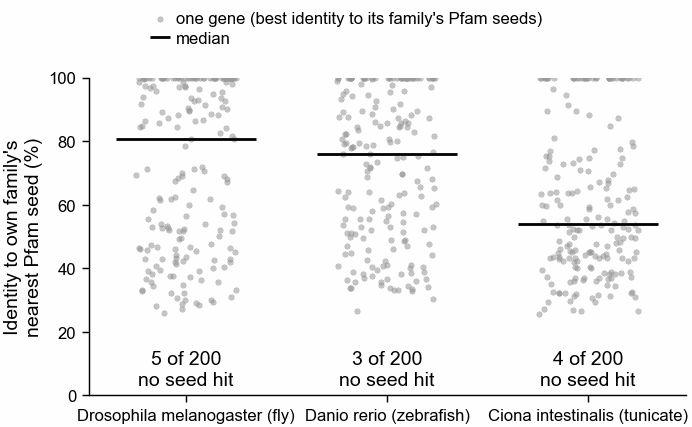

In [2]:
keys = {
    o: pl.read_csv(DATA / "key" / o / "answer_key.tsv", separator="\t")
    for o in ORGANISMS
}
dist = []
for o in ORGANISMS:
    b = pl.read_csv(
        RES / o / "distance" / f"{o}.seed_blastp.tsv",
        separator="\t",
        has_header=False,
        new_columns=[
            "qseqid",
            "sseqid",
            "pident",
            "length",
            "evalue",
            "bitscore",
            "qstart",
            "qend",
            "sstart",
            "send",
        ],
    )
    b = b.with_columns(
        pl.col("sseqid").str.split("|").list.first().alias("seed_family")
    )
    k = keys[o].select(
        pl.col("transcript_id").alias("qseqid"), "pfam_acc", "status", "gene_symbol"
    )
    best = (
        b.join(k, on="qseqid")
        .filter(pl.col("seed_family") == pl.col("pfam_acc"))
        .group_by("qseqid")
        .agg(pl.col("pident").max().alias("seed_identity"))
    )
    dist.append(
        k.join(best, on="qseqid", how="left").with_columns(pl.lit(o).alias("organism"))
    )
dist = pl.concat(dist)
tab = (
    dist.group_by("organism", "status")
    .agg(
        pl.len().alias("genes"),
        pl.col("seed_identity").is_null().sum().alias("no_seed_hit"),
        pl.col("seed_identity").median().alias("median_identity_pct"),
        pl.col("seed_identity").quantile(0.25).alias("q25"),
        pl.col("seed_identity").quantile(0.75).alias("q75"),
    )
    .sort("organism", "status")
)
print(tab)

fig, ax = pf.figure(pf.ONE_COLUMN_MM, 55)
rng = np.random.default_rng(360)
for i, o in enumerate(ORGANISMS):
    d = dist.filter(pl.col("organism") == o)
    v = d["seed_identity"].drop_nulls().to_numpy()
    ax.scatter(
        i + rng.uniform(-0.25, 0.25, v.size),
        v,
        s=5,
        color=pf.GREY,
        alpha=0.6,
        linewidths=0,
        label="one gene (best identity to its family's Pfam seeds)" if i == 0 else None,
    )
    ax.hlines(
        np.median(v),
        i - 0.35,
        i + 0.35,
        color="black",
        label="median" if i == 0 else None,
    )
    nn = d["seed_identity"].is_null().sum()
    ax.text(i, 2, f"{nn} of {d.height}\nno seed hit", ha="center", va="bottom")
ax.set_xticks(range(len(ORGANISMS)), [ORG_LABEL[o] for o in ORGANISMS])
ax.set_ylabel("Identity to own family's\nnearest Pfam seed (%)")
ax.set_ylim(0, 100)
pf.shared_legend(fig, ncol=1)
pf.save(
    fig, FIG / "answer_key_identity_to_pfam_seeds_drosophila_zebrafish_ciona_pfam38"
)

## 2. Did the simulation make the changes it was told to?

polyester's own count of read pairs per transcript, condition B over condition A, by answer-key
status. Up genes should sit near log2 2 (4-fold), down near -2, unchanged near 0. This checks the
input, not either path.

shape: (9, 6)
┌────────────┬───────────┬───────┬─────────────┬───────────┬───────────┐
│ organism   ┆ status    ┆ genes ┆ median_log2 ┆ min       ┆ max       │
│ ---        ┆ ---       ┆ ---   ┆ ---         ┆ ---       ┆ ---       │
│ str        ┆ str       ┆ u32   ┆ f64         ┆ f64       ┆ f64       │
╞════════════╪═══════════╪═══════╪═════════════╪═══════════╪═══════════╡
│ ciona      ┆ down      ┆ 50    ┆ -1.985194   ┆ -2.890641 ┆ -1.481264 │
│ ciona      ┆ unchanged ┆ 100   ┆ -0.02856    ┆ -0.467323 ┆ 0.483387  │
│ ciona      ┆ up        ┆ 50    ┆ 1.969533    ┆ 1.660927  ┆ 2.371856  │
│ drosophila ┆ down      ┆ 50    ┆ -2.008039   ┆ -2.905641 ┆ -1.347679 │
│ drosophila ┆ unchanged ┆ 100   ┆ -0.01256    ┆ -0.324082 ┆ 0.36257   │
│ drosophila ┆ up        ┆ 50    ┆ 2.023579    ┆ 1.735957  ┆ 2.212425  │
│ zebrafish  ┆ down      ┆ 50    ┆ -1.969132   ┆ -2.554813 ┆ -1.528007 │
│ zebrafish  ┆ unchanged ┆ 100   ┆ 0.011744    ┆ -0.532711 ┆ 0.294351  │
│ zebrafish  ┆ up        ┆ 50    ┆ 2.

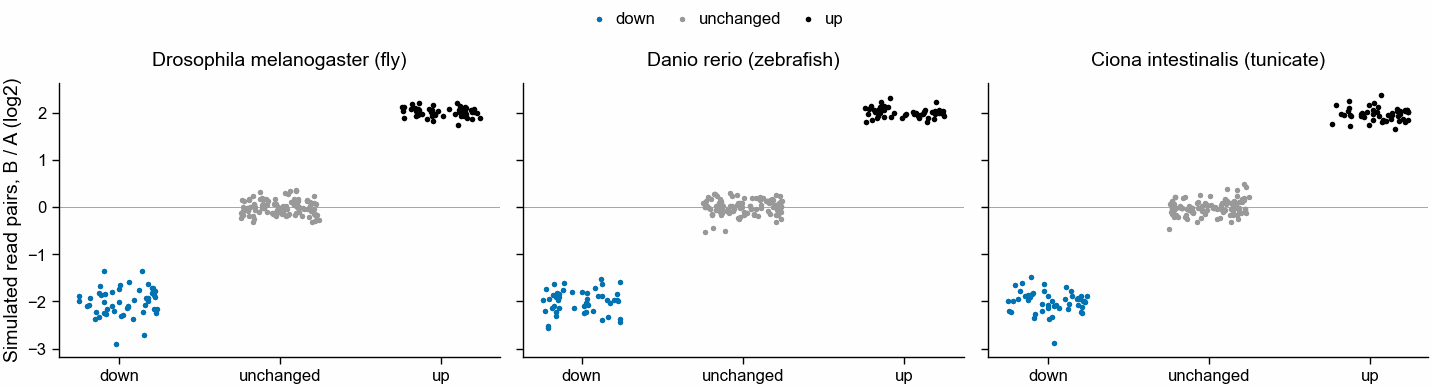

In [3]:
tc = []
for o in ORGANISMS:
    t = pl.read_csv(RES / o / "reads" / "true_counts.tsv", separator="\t")
    a = t.select([f"sample_0{i}" for i in (1, 2, 3)]).sum_horizontal()
    b = t.select([f"sample_0{i}" for i in (4, 5, 6)]).sum_horizontal()
    t = t.with_columns(
        ((b + 0.5) / (a + 0.5)).log(2).alias("log2_b_over_a"),
        pl.lit(o).alias("organism"),
    )
    tc.append(t.join(keys[o].select("transcript_id", "status"), on="transcript_id"))
tc = pl.concat(tc)
print(
    tc.group_by("organism", "status")
    .agg(
        pl.len().alias("genes"),
        pl.col("log2_b_over_a").median().alias("median_log2"),
        pl.col("log2_b_over_a").min().alias("min"),
        pl.col("log2_b_over_a").max().alias("max"),
    )
    .sort("organism", "status")
)
STATUS_COLOUR = {"up": "#000000", "down": "#0072B2", "unchanged": pf.GREY}
fig, axs = pf.figure(pf.TWO_COLUMN_MM, 50, ncols=3, sharey=True)
for ax, o in zip(axs, ORGANISMS):
    for j, st in enumerate(["down", "unchanged", "up"]):
        v = tc.filter((pl.col("organism") == o) & (pl.col("status") == st))[
            "log2_b_over_a"
        ].to_numpy()
        ax.scatter(
            j + rng.uniform(-0.25, 0.25, v.size),
            v,
            s=4,
            color=STATUS_COLOUR[st],
            linewidths=0,
            label=st,
        )
    ax.axhline(0, color=pf.GREY, lw=0.3)
    ax.set_xticks(range(3), ["down", "unchanged", "up"])
    ax.set_title(ORG_LABEL[o])
axs[0].set_ylabel("Simulated read pairs, B / A (log2)")
pf.shared_legend(fig, ncol=3)
pf.save(fig, FIG / "simulated_fold_change_by_key_status_polyester")

## 3. Recovery of the 100 changed domains, per path and kmerseek setting

Each row is one way of finding changed domains. The coloured diamond is the real labels; the grey
circles are the 9 label swaps. Higher is better on the real labels. On the swaps, a third of the
change is still there, so some recovery is expected, but less. The standard path is the bottom row.
The reduced-alphabet setting that enters the rule is marked.

shape: (53, 6)
┌───────────┬──────────────────────────────┬────────┬───────────┬─────────┬───────────┐
│ organism  ┆ setting                      ┆ status ┆ recovered ┆ outside ┆ n_queries │
│ ---       ┆ ---                          ┆ ---    ┆ ---       ┆ ---     ┆ ---       │
│ str       ┆ str                          ┆ str    ┆ i64       ┆ i64     ┆ i64       │
╞═══════════╪══════════════════════════════╪════════╪═══════════╪═════════╪═══════════╡
│ ciona     ┆ trinity+diamond              ┆ ok     ┆ 87        ┆ 82      ┆ 215       │
│ ciona     ┆ hsdm17.k7                    ┆ fitted ┆ 61        ┆ 17      ┆ 10971     │
│ ciona     ┆ mmseqs12.k8                  ┆ fitted ┆ 61        ┆ 11      ┆ 10971     │
│ ciona     ┆ sdm12.k8                     ┆ fitted ┆ 59        ┆ 28      ┆ 10971     │
│ ciona     ┆ uniprot18.k7                 ┆ fitted ┆ 50        ┆ 7       ┆ 10971     │
│ …         ┆ …                            ┆ …      ┆ …         ┆ …       ┆ …         │
│ zebrafish ┆ hp_

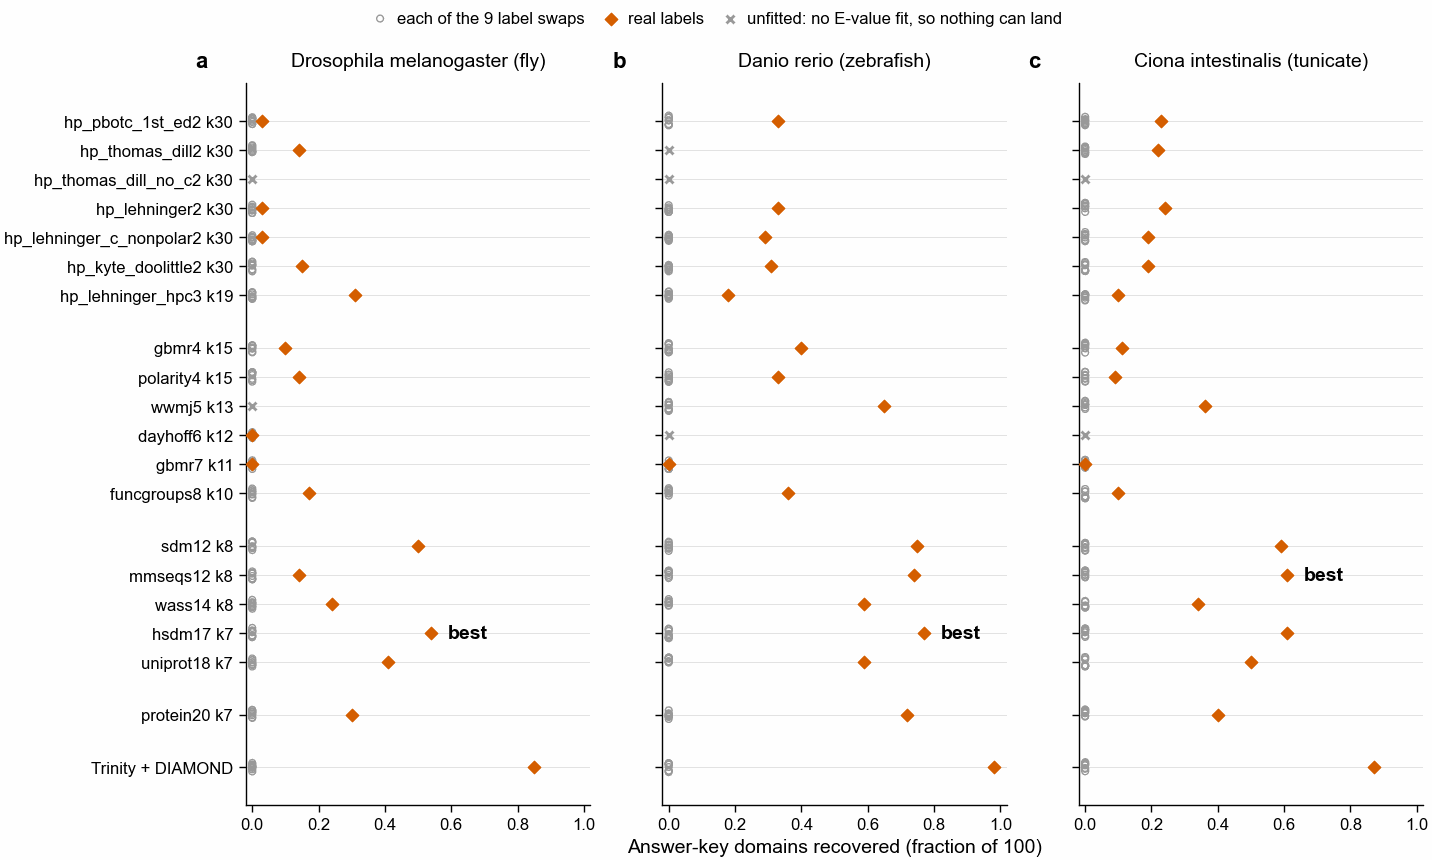

In [4]:
REAL = pf.OKABE_ITO["vermillion"]


def setting_axis(ax):
    y, ticks, labels, ypos = 0, [], [], {}
    for lab, sid, g in ROWS[::-1]:
        ypos[sid] = y
        ticks.append(y)
        labels.append(lab)
        y += 1
        nxt = (
            ROWS[::-1][ROWS[::-1].index((lab, sid, g)) + 1][2]
            if (lab, sid, g) != ROWS[0]
            else g
        )
        if nxt != g:
            y += 0.8
    ax.set_yticks(ticks, labels)
    for t in ticks:
        ax.axhline(t, color="#dddddd", lw=0.3, zorder=0)
    return ypos


def pick_r(org):
    p = primary.filter(
        (pl.col("organism") == org)
        & (pl.col("path") == "kmerseek")
        & (pl.col("labelling") == "real")
        & (pl.col("setting") != f"protein20.k{K_OF['protein20']}")
    )
    return p.sort(
        ["recovered", "outside", "setting"], descending=[True, False, False]
    ).row(0, named=True)


def dot_panel(ax, org, col, xlabel):
    ypos = setting_axis(ax)
    d = primary.filter(pl.col("organism") == org)
    for _, sid, _ in ROWS:
        s = d.filter(pl.col("setting") == sid)
        if s.height == 0:
            ax.scatter(
                [0],
                [ypos[sid]],
                marker="x",
                color=pf.GREY,
                s=8,
                label="unfitted: no E-value fit, so nothing can land",
            )
            continue
        sw = s.filter(pl.col("labelling") != "real")[col].to_numpy()
        ax.scatter(
            sw,
            np.full(sw.size, ypos[sid]) + rng.uniform(-0.18, 0.18, sw.size),
            s=6,
            facecolors="none",
            edgecolors=pf.GREY,
            linewidths=0.5,
            label="each of the 9 label swaps",
        )
        ax.scatter(
            s.filter(pl.col("labelling") == "real")[col].to_numpy(),
            [ypos[sid]],
            marker="D",
            s=10,
            color=REAL,
            zorder=3,
            label="real labels",
        )
    r = pick_r(org)
    ax.annotate(
        "best",
        (r[col], ypos[r["setting"]]),
        xytext=(6, 0),
        textcoords="offset points",
        va="center",
        fontweight="bold",
    )
    ax.set_xlabel(xlabel)
    ax.set_title(ORG_LABEL[org])


fig, axs = pf.figure(pf.TWO_COLUMN_MM, 110, ncols=3, sharey=True)
for ax, o in zip(axs, ORGANISMS):
    dot_panel(
        ax,
        o,
        "recovery_fraction",
        "Answer-key domains recovered (fraction of 100)" if ax is axs[1] else "",
    )
    ax.set_xlim(-0.02, 1.02)
pf.shared_legend(fig)
for ax, letter in zip(axs, "abc"):
    pf.panel_label(ax, letter)
pf.save(
    fig,
    FIG
    / "recovery_per_path_and_kmerseek_setting_real_vs_swaps_drosophila_zebrafish_ciona_swissprot_pfam",
)
print(
    primary.filter(pl.col("labelling") == "real")
    .select("organism", "setting", "status", "recovered", "outside", "n_queries")
    .sort("organism", "recovered", descending=[False, True])
)

## 4. Changed domains outside the key, real labels vs swaps

Same rows. The count of Pfam families a path calls changed that are not answer-key domains. Lower is better for agreement with the answer key; biological correctness outside that key
was not checked. A setting whose real-label count is no higher than its
swaps lands outside the key at the same rate whether or not anything changed.

shape: (53, 5)
┌───────────┬──────────────────────────────┬──────────────┬─────────────────────┬──────────────────┐
│ organism  ┆ setting                      ┆ outside_real ┆ outside_swap_median ┆ outside_swap_max │
│ ---       ┆ ---                          ┆ ---          ┆ ---                 ┆ ---              │
│ str       ┆ str                          ┆ i64          ┆ f64                 ┆ i64              │
╞═══════════╪══════════════════════════════╪══════════════╪═════════════════════╪══════════════════╡
│ ciona     ┆ funcgroups8.k10              ┆ 0            ┆ 0.0                 ┆ 0                │
│ ciona     ┆ polarity4.k15                ┆ 0            ┆ 0.0                 ┆ 0                │
│ ciona     ┆ hp_lehninger_c_nonpolar2.k30 ┆ 1            ┆ 0.0                 ┆ 0                │
│ ciona     ┆ hp_thomas_dill2.k30          ┆ 1            ┆ 0.0                 ┆ 0                │
│ ciona     ┆ protein20.k7                 ┆ 1            ┆ 0.0             

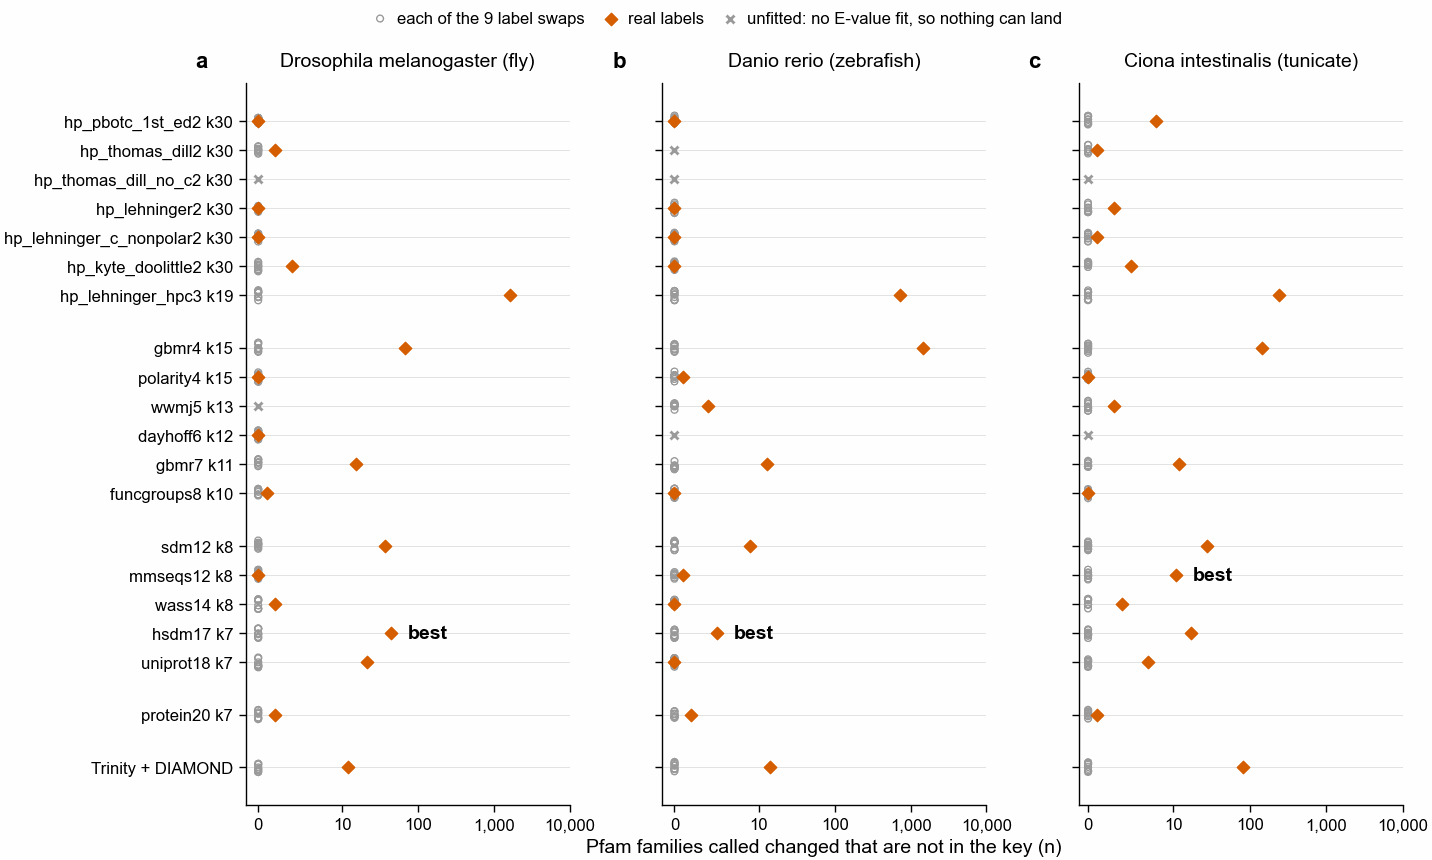

In [5]:
fig, axs = pf.figure(pf.TWO_COLUMN_MM, 110, ncols=3, sharey=True)
for ax, o in zip(axs, ORGANISMS):
    dot_panel(
        ax,
        o,
        "outside",
        (
            "Pfam families called changed that are not in the key (n)"
            if ax is axs[1]
            else ""
        ),
    )
    ax.set_xscale("symlog", linthresh=10)
    ax.set_xticks([0, 10, 100, 1000, 10000], ["0", "10", "100", "1,000", "10,000"])
pf.shared_legend(fig)
for ax, letter in zip(axs, "abc"):
    pf.panel_label(ax, letter)
pf.save(
    fig,
    FIG
    / "outside_key_calls_per_path_and_kmerseek_setting_real_vs_swaps_drosophila_zebrafish_ciona_swissprot_pfam",
)
print(
    primary.group_by("organism", "setting")
    .agg(
        pl.col("outside")
        .filter(pl.col("labelling") == "real")
        .first()
        .alias("outside_real"),
        pl.col("outside")
        .filter(pl.col("labelling") != "real")
        .median()
        .alias("outside_swap_median"),
        pl.col("outside")
        .filter(pl.col("labelling") != "real")
        .max()
        .alias("outside_swap_max"),
    )
    .sort("organism", "outside_real")
)

## 5. The rule, in Drosophila, with zebrafish and Ciona beside it

The two inequalities are unchanged. Drosophila's column is the verdict; the other two are
reported. An unfitted setting (no Karlin-Altschul fit, so no E-value) cannot land anything and
is listed, not counted as a zero. Every swap gives zero changed k-mers, so R's swap median is 0
and part 2 passes even for zero real recovery: it adds no evidence here. That was not foreseen
when the rule was frozen; the rule is kept and the verdict rests on part 1.

shape: (13, 4)
┌───────────────────────────┬────────────┬───────────┬─────────────┐
│ column                    ┆ drosophila ┆ zebrafish ┆ ciona       │
│ ---                       ┆ ---        ┆ ---       ┆ ---         │
│ str                       ┆ str        ┆ str       ┆ str         │
╞═══════════════════════════╪════════════╪═══════════╪═════════════╡
│ organism                  ┆ drosophila ┆ zebrafish ┆ ciona       │
│ R                         ┆ hsdm17.k7  ┆ hsdm17.k7 ┆ mmseqs12.k8 │
│ R_recovered               ┆ 54         ┆ 77        ┆ 61          │
│ standard_recovered        ┆ 85         ┆ 98        ┆ 87          │
│ part1_R_at_least_standard ┆ false      ┆ false     ┆ false       │
│ …                         ┆ …          ┆ …         ┆ …           │
│ n_swaps                   ┆ 9          ┆ 9         ┆ 9           │
│ verdict                   ┆ FAIL       ┆ FAIL      ┆ FAIL        │
│ evaluable_reduced         ┆ 16         ┆ 15        ┆ 16          │
│ complete         

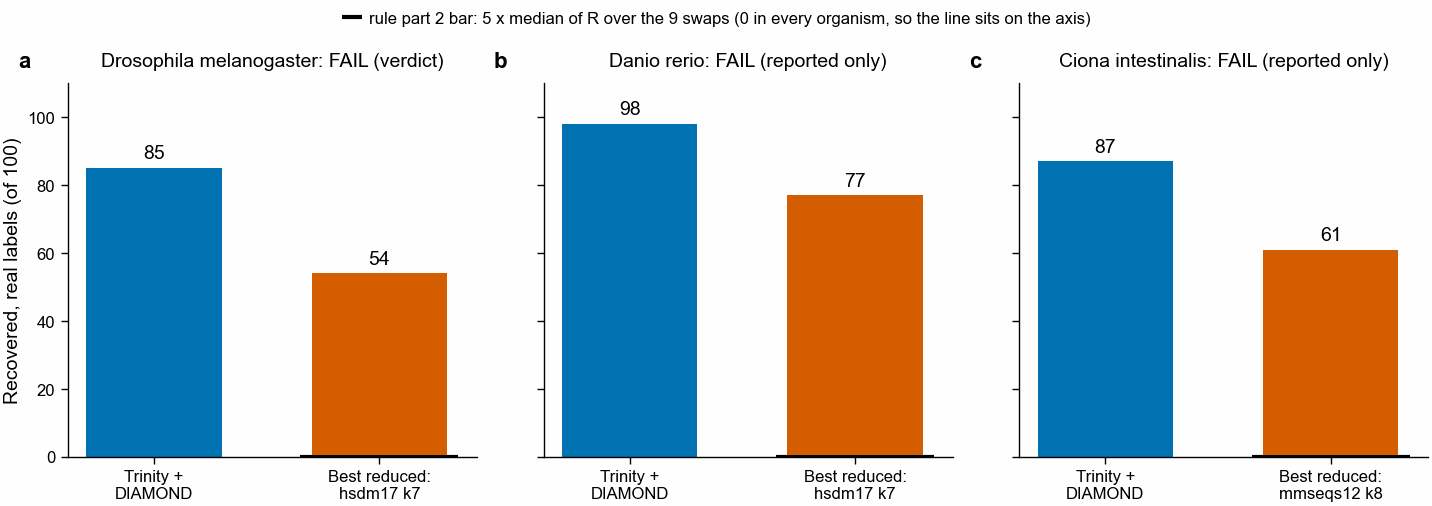

In [6]:
def verdict(org):
    r = pick_r(org)
    std = primary.filter(
        (pl.col("organism") == org)
        & (pl.col("path") == "standard")
        & (pl.col("labelling") == "real")
    ).row(0, named=True)
    sw = primary.filter(
        (pl.col("organism") == org)
        & (pl.col("setting") == r["setting"])
        & (pl.col("labelling") != "real")
    )["recovered"]
    part1 = r["recovery_fraction"] >= std["recovery_fraction"]
    part2 = r["recovered"] >= SWAP_FACTOR * sw.median()
    return dict(
        organism=org,
        R=r["setting"],
        R_recovered=r["recovered"],
        standard_recovered=std["recovered"],
        part1_R_at_least_standard=part1,
        R_swap_median=float(sw.median()),
        R_swap_max=int(sw.max()),
        part2_at_least_5x_swaps=part2,
        n_swaps=sw.len(),
        verdict="PASS" if part1 and part2 else "FAIL",
        evaluable_reduced=primary.filter(
            (pl.col("organism") == org)
            & (pl.col("path") == "kmerseek")
            & (pl.col("labelling") == "real")
            & ~pl.col("setting").str.starts_with("protein20")
        ).height,
        complete=not missing[org],
        insufficient_evidence=std["recovered"] == 0,
    )


V = pl.DataFrame([verdict(o) for o in ORGANISMS])
print(V.transpose(include_header=True, column_names=ORGANISMS))
print(
    f"\nVerdict ({VERDICT_ORG}):",
    V.filter(pl.col("organism") == VERDICT_ORG)["verdict"][0],
)

fig, axs = pf.figure(pf.TWO_COLUMN_MM, 65, ncols=3, sharey=True)
for ax, (_, v) in zip(axs, enumerate(V.iter_rows(named=True))):
    ax.bar(
        [0, 1],
        [v["standard_recovered"], v["R_recovered"]],
        color=[pf.OKABE_ITO["blue"], REAL],
        width=0.6,
    )
    for x, y in [(0, v["standard_recovered"]), (1, v["R_recovered"])]:
        ax.text(x, y + 1.5, str(y), ha="center", va="bottom")
    ax.hlines(
        SWAP_FACTOR * v["R_swap_median"],
        0.65,
        1.35,
        color="black",
        lw=1.5,
        label=f"rule part 2 bar: {SWAP_FACTOR} x median of R over the 9 swaps (0 in every organism, so the line sits on the axis)",
    )
    ax.set_xticks(
        [0, 1], ["Trinity +\nDIAMOND", f"Best reduced:\n{v['R'].replace('.k', ' k')}"]
    )
    role = "verdict" if v["organism"] == VERDICT_ORG else "reported only"
    ax.set_title(f"{ORG_LABEL[v['organism']].split(' (')[0]}: {v['verdict']} ({role})")
    ax.set_ylim(0, N_KEY + 10)
axs[0].set_ylabel("Recovered, real labels (of 100)")
pf.shared_legend(fig, ncol=1)
for ax, letter in zip(axs, "abc"):
    pf.panel_label(ax, letter)
pf.save(
    fig,
    FIG / "verdict_best_reduced_alphabet_vs_trinity_diamond_drosophila_zebrafish_ciona",
)

## 6. Recovery by distance from the Pfam seeds

Answer-key genes grouped by their identity to their family's nearest Pfam seed (section 1). For each
group, the fraction recovered on real labels by the standard path, by R and by protein20. Read: a
reduced alphabet is meant to help most for genes far from Pfam (left); if R's line is not above the
standard path's at the left, that advantage is not there in this data.

shape: (42, 6)
┌───────────┬─────────────────┬───────┬───────┬───────────┬──────────┐
│ organism  ┆ setting         ┆ bin   ┆ genes ┆ recovered ┆ fraction │
│ ---       ┆ ---             ┆ ---   ┆ ---   ┆ ---       ┆ ---      │
│ str       ┆ str             ┆ str   ┆ i64   ┆ i64       ┆ f64      │
╞═══════════╪═════════════════╪═══════╪═══════╪═══════════╪══════════╡
│ ciona     ┆ mmseqs12.k8     ┆ 30-40 ┆ 16    ┆ 10        ┆ 0.625    │
│ ciona     ┆ mmseqs12.k8     ┆ 40-50 ┆ 24    ┆ 11        ┆ 0.458333 │
│ ciona     ┆ mmseqs12.k8     ┆ 50-60 ┆ 14    ┆ 9         ┆ 0.642857 │
│ ciona     ┆ mmseqs12.k8     ┆ <30   ┆ 3     ┆ 2         ┆ 0.666667 │
│ ciona     ┆ mmseqs12.k8     ┆ >=60  ┆ 43    ┆ 29        ┆ 0.674419 │
│ …         ┆ …               ┆ …     ┆ …     ┆ …         ┆ …        │
│ zebrafish ┆ protein20.k7    ┆ >=60  ┆ 63    ┆ 48        ┆ 0.761905 │
│ zebrafish ┆ trinity+diamond ┆ 30-40 ┆ 13    ┆ 13        ┆ 1.0      │
│ zebrafish ┆ trinity+diamond ┆ 40-50 ┆ 13    ┆ 12        ┆ 0.

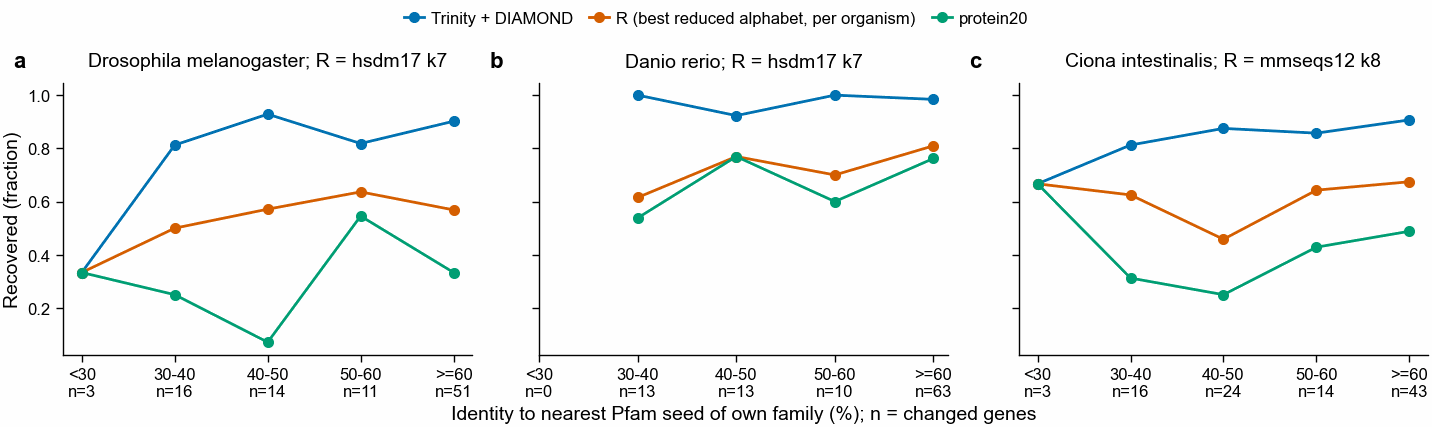

In [7]:
BINS = [0, 30, 40, 50, 60, 101]
BIN_LABELS = ["<30", "30-40", "40-50", "50-60", ">=60"]


def recovered_families(org, setting):
    if setting == "trinity+diamond":
        c = pl.read_csv(
            RES / org / "standard" / f"{org}.standard.calls.tsv", separator="\t"
        )
    else:
        c = pl.read_csv(
            RES / org / "landings" / f"{org}.{setting}.primary_landings.tsv.gz",
            separator="\t",
        )
        c = c.filter(pl.col("region_evalue") <= PRIMARY_E)
    return set(c.filter(pl.col("labelling") == "real")["pfam_acc"].to_list())


rows = []
for o in ORGANISMS:
    d = dist.filter(
        (pl.col("organism") == o) & (pl.col("status") != "unchanged")
    ).with_columns(
        pl.col("seed_identity")
        .cut(BINS[1:-1], labels=BIN_LABELS, left_closed=True)
        .alias("bin")
    )
    for sid in [
        "trinity+diamond",
        pick_r(o)["setting"],
        f"protein20.k{K_OF['protein20']}",
    ]:
        fams = recovered_families(o, sid)
        for b, g in d.drop_nulls("bin").group_by("bin"):
            rows.append(
                dict(
                    organism=o,
                    setting=sid,
                    bin=b[0],
                    genes=g.height,
                    recovered=int(g["pfam_acc"].is_in(list(fams)).sum()),
                )
            )
by_dist = pl.DataFrame(rows).with_columns(
    (pl.col("recovered") / pl.col("genes")).alias("fraction")
)
print(by_dist.sort("organism", "setting", "bin"))
fig, axs = pf.figure(pf.TWO_COLUMN_MM, 55, ncols=3, sharey=True)
COL = {
    "Trinity + DIAMOND": pf.OKABE_ITO["blue"],
    "R": REAL,
    "protein20": pf.OKABE_ITO["bluish_green"],
}
for ax, o in zip(axs, ORGANISMS):
    r = pick_r(o)["setting"]
    for sid, name in [
        ("trinity+diamond", "Trinity + DIAMOND"),
        (r, "R"),
        (f"protein20.k{K_OF['protein20']}", "protein20"),
    ]:
        s = (
            by_dist.filter((pl.col("organism") == o) & (pl.col("setting") == sid))
            .with_columns(
                pl.col("bin")
                .cast(pl.Utf8)
                .replace({l: i for i, l in enumerate(BIN_LABELS)})
                .cast(pl.Int32)
                .alias("x")
            )
            .sort("x")
        )
        lab = "R (best reduced alphabet, per organism)" if name == "R" else name
        ax.plot(s["x"], s["fraction"], marker="o", color=COL[name], label=lab)
    n_of = dict(
        by_dist.filter(pl.col("organism") == o)
        .group_by("bin")
        .agg(pl.col("genes").first())
        .iter_rows()
    )
    ax.set_xticks(
        range(len(BIN_LABELS)), [f"{b}\nn={n_of.get(b, 0)}" for b in BIN_LABELS]
    )
    ax.set_xlabel(
        "Identity to nearest Pfam seed of own family (%); n = changed genes"
        if ax is axs[1]
        else ""
    )
    ax.set_title(
        f"{ORG_LABEL[o].split(' (')[0]}; R = {pick_r(o)['setting'].replace('.k', ' k')}"
    )
axs[0].set_ylabel("Recovered (fraction)")
pf.shared_legend(fig)
for ax, letter in zip(axs, "abc"):
    pf.panel_label(ax, letter)
pf.save(fig, FIG / "recovery_by_identity_to_pfam_seed_drosophila_zebrafish_ciona")

## 7. Not part of the rule: the E-value cut-off

The rule counts a landing at `region_evalue` at most 1. Here the same counts at other cut-offs,
including 10, for R and protein20 in Drosophila, real labels and swap median. This shows whether the
verdict would move with the cut-off; it does not change the verdict.

shape: (12, 6)
┌────────────┬──────────────┬───────────────┬────────────────┬──────────────────────┬──────────────┐
│ organism   ┆ setting      ┆ evalue_cutoff ┆ recovered_real ┆ recovered_swap_media ┆ outside_real │
│ ---        ┆ ---          ┆ ---           ┆ ---            ┆ n                    ┆ ---          │
│ str        ┆ str          ┆ f64           ┆ i64            ┆ ---                  ┆ i64          │
│            ┆              ┆               ┆                ┆ f64                  ┆              │
╞════════════╪══════════════╪═══════════════╪════════════════╪══════════════════════╪══════════════╡
│ drosophila ┆ hsdm17.k7    ┆ 0.000001      ┆ 29             ┆ 0.0                  ┆ 3            │
│ drosophila ┆ hsdm17.k7    ┆ 0.0001        ┆ 34             ┆ 0.0                  ┆ 4            │
│ drosophila ┆ hsdm17.k7    ┆ 0.01          ┆ 47             ┆ 0.0                  ┆ 11           │
│ drosophila ┆ hsdm17.k7    ┆ 1.0           ┆ 54             ┆ 0.0          

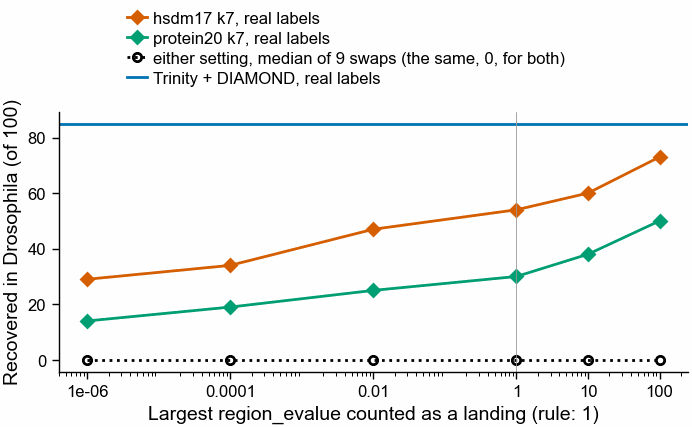

In [8]:
sweep = (
    summary.filter((pl.col("path") == "kmerseek"))
    .group_by("organism", "setting", "evalue_cutoff")
    .agg(
        pl.col("recovered")
        .filter(pl.col("labelling") == "real")
        .first()
        .alias("recovered_real"),
        pl.col("recovered")
        .filter(pl.col("labelling") != "real")
        .median()
        .alias("recovered_swap_median"),
        pl.col("outside")
        .filter(pl.col("labelling") == "real")
        .first()
        .alias("outside_real"),
    )
    .sort("organism", "setting", "evalue_cutoff")
)
show = [pick_r(VERDICT_ORG)["setting"], f"protein20.k{K_OF['protein20']}"]
print(sweep.filter((pl.col("organism") == VERDICT_ORG) & pl.col("setting").is_in(show)))
std_c = primary.filter(
    (pl.col("organism") == VERDICT_ORG)
    & (pl.col("path") == "standard")
    & (pl.col("labelling") == "real")
)["recovered"][0]
fig, ax = pf.figure(pf.ONE_COLUMN_MM, 55)
for sid, c in zip(show, [REAL, pf.OKABE_ITO["bluish_green"]]):
    s = sweep.filter((pl.col("organism") == VERDICT_ORG) & (pl.col("setting") == sid))
    nm = sid.replace(".k", " k")
    ax.plot(
        s["evalue_cutoff"],
        s["recovered_real"],
        marker="D",
        color=c,
        label=f"{nm}, real labels",
    )
s = (
    sweep.filter((pl.col("organism") == VERDICT_ORG) & pl.col("setting").is_in(show))
    .group_by("evalue_cutoff")
    .agg(pl.col("recovered_swap_median").max())
    .sort("evalue_cutoff")
)
ax.plot(
    s["evalue_cutoff"],
    s["recovered_swap_median"],
    marker="o",
    mfc="none",
    color="black",
    ls=":",
    label="either setting, median of 9 swaps (the same, 0, for both)",
)
ax.axhline(std_c, color=pf.OKABE_ITO["blue"], label="Trinity + DIAMOND, real labels")
ax.axvline(PRIMARY_E, color=pf.GREY, lw=0.3)
ax.set_xscale("log")
cuts = sweep["evalue_cutoff"].unique().sort().to_list()
ax.set_xticks(cuts, [f"{c:g}" for c in cuts])
ax.set_xlabel("Largest region_evalue counted as a landing (rule: 1)")
ax.set_ylabel("Recovered in Drosophila (of 100)")
pf.shared_legend(fig, ncol=1)
pf.save(fig, FIG / "recovery_vs_region_evalue_cutoff_drosophila_swissprot_pfam")

# Summary and Conclusions

## Background

This test simulates RNA-seq reads in which 100 known Pfam families change, then asks whether
k-mers that change between conditions, landed on Pfam domains by kmerseek in a reduced
alphabet, find those families as well as Trinity assembly, DIAMOND and the best hit's Pfam
domains. Drosophila decides the verdict; zebrafish and Ciona are reported beside it.

## Summary and Conclusions

- **FAIL in Drosophila.** The best reduced-alphabet setting, hsdm17 k7, recovers 54 of the 100
  changed families; Trinity + DIAMOND recovers 85.
- Zebrafish and Ciona fail the same way: hsdm17 k7 recovers 77 against 98 in zebrafish, and
  mmseqs12 k8 recovers 61 against 87 in Ciona (tied with hsdm17 k7 at 61; mmseqs12 has fewer
  families outside the key, 11 against 17).
- No setting, reduced or protein20, reaches the assembly path at the frozen cut-off
  (`region_evalue` at most 1) in any organism.
- The label swaps test nothing here: all 9 swaps give 0 changed k-mers and 0 changed
  transcripts in all three organisms, so part 2 of the rule passes automatically.

## Analysis Details

At `region_evalue` at most 10, the best reduced setting reaches 65 in Drosophila
(hp_lehninger_hpc3 k19, with 5,258 families outside the key), 80 in zebrafish and 70 in Ciona,
all still below the assembly path. At 100, hp_lehninger_hpc3 k19 reaches 95 in Drosophila, but
lands on 11,709 families outside the key: it lands almost everywhere, so its recovery says
nothing about which domains changed.

Drosophila's changed genes are about as close to their Pfam seeds as zebrafish's (median
identity 66-68% against 70-72%) and closer than Ciona's (54%). Its kmerseek recovery is still
the lowest of the three, so distance from Pfam does not explain the gap.

gbmr7 k11 lands on none of the 100 changed families in any organism, while landing on 12 to 15
families outside the key. Unfitted settings (no Karlin-Altschul fit, so no E-values and no
landings): hp_thomas_dill_no_c2 k30 and wwmj5 k13 in Drosophila; dayhoff6 k12,
hp_thomas_dill2 k30 and hp_thomas_dill_no_c2 k30 in zebrafish; dayhoff6 k12 and
hp_thomas_dill_no_c2 k30 in Ciona.

## Supplementary Information

The k-mer path joins overlapping changed 31-mers into short contigs before translating them,
so it avoids whole-transcriptome assembly but still assembles locally. The standard path
borrows every Pfam domain of its best hit, which adds families outside the key (12 in
Drosophila, 14 in zebrafish, 82 in Ciona). The kmerseek index fits its E-values against
shuffled sequences by default; the answer key and label swaps use no shuffling.

Ciona was the first deciding organism. Olga replaced it with Drosophila on 2026-11-01 because
Ciona is poorly annotated, after the Ciona and zebrafish verdicts (both FAIL) had been
computed. The plan records this. The verdict would be FAIL under any of the three.

## References

- [Frozen design and rule](360_data/preregistered.md).
- [Zebrafish switch, 2026-10-22](360_data/species_change_2026-10-22.md).
- [Independent check of Ciona and zebrafish](360_data/adversarial_review.md).
- [Independent check of Drosophila](360_data/adversarial_review_drosophila.md).

In [9]:
summary_md = "# Summary and Conclusions\n\n## Background\n\nThis test simulates RNA-seq reads in which 100 known Pfam families change, then asks whether\nk-mers that change between conditions, landed on Pfam domains by kmerseek in a reduced\nalphabet, find those families as well as Trinity assembly, DIAMOND and the best hit's Pfam\ndomains. Drosophila decides the verdict; zebrafish and Ciona are reported beside it.\n\n## Summary and Conclusions\n\n- **FAIL in Drosophila.** The best reduced-alphabet setting, hsdm17 k7, recovers 54 of the 100\n  changed families; Trinity + DIAMOND recovers 85.\n- Zebrafish and Ciona fail the same way: hsdm17 k7 recovers 77 against 98 in zebrafish, and\n  mmseqs12 k8 recovers 61 against 87 in Ciona (tied with hsdm17 k7 at 61; mmseqs12 has fewer\n  families outside the key, 11 against 17).\n- No setting, reduced or protein20, reaches the assembly path at the frozen cut-off\n  (`region_evalue` at most 1) in any organism.\n- The label swaps test nothing here: all 9 swaps give 0 changed k-mers and 0 changed\n  transcripts in all three organisms, so part 2 of the rule passes automatically.\n\n## Analysis Details\n\nAt `region_evalue` at most 10, the best reduced setting reaches 65 in Drosophila\n(hp_lehninger_hpc3 k19, with 5,258 families outside the key), 80 in zebrafish and 70 in Ciona,\nall still below the assembly path. At 100, hp_lehninger_hpc3 k19 reaches 95 in Drosophila, but\nlands on 11,709 families outside the key: it lands almost everywhere, so its recovery says\nnothing about which domains changed.\n\nDrosophila's changed genes are about as close to their Pfam seeds as zebrafish's (median\nidentity 66-68% against 70-72%) and closer than Ciona's (54%). Its kmerseek recovery is still\nthe lowest of the three, so distance from Pfam does not explain the gap.\n\ngbmr7 k11 lands on none of the 100 changed families in any organism, while landing on 12 to 15\nfamilies outside the key. Unfitted settings (no Karlin-Altschul fit, so no E-values and no\nlandings): hp_thomas_dill_no_c2 k30 and wwmj5 k13 in Drosophila; dayhoff6 k12,\nhp_thomas_dill2 k30 and hp_thomas_dill_no_c2 k30 in zebrafish; dayhoff6 k12 and\nhp_thomas_dill_no_c2 k30 in Ciona.\n\n## Supplementary Information\n\nThe k-mer path joins overlapping changed 31-mers into short contigs before translating them,\nso it avoids whole-transcriptome assembly but still assembles locally. The standard path\nborrows every Pfam domain of its best hit, which adds families outside the key (12 in\nDrosophila, 14 in zebrafish, 82 in Ciona). The kmerseek index fits its E-values against\nshuffled sequences by default; the answer key and label swaps use no shuffling.\n\nCiona was the first deciding organism. Olga replaced it with Drosophila on 2026-11-01 because\nCiona is poorly annotated, after the Ciona and zebrafish verdicts (both FAIL) had been\ncomputed. The plan records this. The verdict would be FAIL under any of the three.\n\n## References\n\n- [Frozen design and rule](360_data/preregistered.md).\n- [Zebrafish switch, 2026-10-22](360_data/species_change_2026-10-22.md).\n- [Independent check of Ciona and zebrafish](360_data/adversarial_review.md).\n- [Independent check of Drosophila](360_data/adversarial_review_drosophila.md).\n"
print(summary_md)

# Summary and Conclusions

## Background

This test simulates RNA-seq reads in which 100 known Pfam families change, then asks whether
k-mers that change between conditions, landed on Pfam domains by kmerseek in a reduced
alphabet, find those families as well as Trinity assembly, DIAMOND and the best hit's Pfam
domains. Drosophila decides the verdict; zebrafish and Ciona are reported beside it.

## Summary and Conclusions

- **FAIL in Drosophila.** The best reduced-alphabet setting, hsdm17 k7, recovers 54 of the 100
  changed families; Trinity + DIAMOND recovers 85.
- Zebrafish and Ciona fail the same way: hsdm17 k7 recovers 77 against 98 in zebrafish, and
  mmseqs12 k8 recovers 61 against 87 in Ciona (tied with hsdm17 k7 at 61; mmseqs12 has fewer
  families outside the key, 11 against 17).
- No setting, reduced or protein20, reaches the assembly path at the frozen cut-off
  (`region_evalue` at most 1) in any organism.
- The label swaps test nothing here: all 9 swaps give 0 changed k-m